# Практична робота №19
## Класифікація математичних моделей: аналіз прикладів, перевірка адекватності моделі

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тема:** прогноз місячного споживання електроенергії за середньомісячною температурою

**Мета:** класифікувати модель за незалежними ознаками; підібрати лінійну залежність методом найменших квадратів; перевірити точність і структуру залишків; розмежувати верифікацію та валідацію.

> Вихідні спостереження є **синтетичними навчальними даними**, а не фактичними вимірюваннями енергоспоживання міста.

### Вихідні параметри варіанта

| Параметр | Значення |
|---|---:|
| Місто | Дніпро |
| Номер варіанта / `seed` | 5 |
| Середньорічна температура | 10,0 °C |
| Сезонна амплітуда | 14,0 °C |
| Базове споживання | 2900 МВт·год |
| Коефіцієнт зміни споживання `k` | 42 МВт·год/°C |
| Стандартне відхилення шуму | 50 МВт·год |

**Формула генерації:** `consumption = base_consumption - k * (temp - base_temp) + noise`.

Для порівнянності з умовою використовуємо `np.random.seed(5)`, а також порядок створення й округлення значень із методичних вказівок.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.random.seed(5)
city = "Дніпро"
base_temp = 10.0
amplitude = 14.0
base_consumption = 2900
k = 42
noise_sd = 50

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months,
    "температура": temp,
    "споживання_МВтгод": consumption,
})
print(f"Місто: {city}; форма набору: {city_data.shape}; унікальних місяців: {city_data['місяць'].nunique()}")
display(city_data)

assert city_data.shape == (12, 3)
assert city_data['споживання_МВтгод'].notna().all()

Місто: Дніпро; форма набору: (12, 3); унікальних місяців: 12


,місяць,температура,споживання_МВтгод
0,1,-3.8,3462.0
1,2,-2.3,3447.0
2,3,4.2,3060.0
3,4,9.9,2869.0
4,5,17.1,2659.0
5,6,22.9,2451.0
6,7,23.5,2257.0
7,8,21.8,2437.0
8,9,17.1,2553.0
9,10,9.8,2866.0


## Завдання 1. Класифікація сценарію

**1. Детермінована чи стохастична?** Повна модель — **стохастична**: вираз `base_consumption − k·(temp − base_temp)` задає детерміновану середню залежність, але до споживання додано нормально розподілений випадковий шум із σ = 50 МВт·год. Тому навіть за однакової температури можливі різні спостережені значення споживання.

**2. Балансова, оптимізаційна, імітаційна чи жодна з перелічених?** Модель **описова/прогнозна статистична** (жодна з трьох): вона не задає закон збереження ресурсу; не максимізує чи мінімізує цільову функцію; не моделює покроково роботу енергосистеми. Генерація синтетичних спостережень із шумом для перевірки моделі сама собою не робить модель динамічною імітаційною моделлю.

**3. Статична чи динамічна?** **Статична**, тому що прогноз для кожного місяця залежить тільки від температури цього ж місяця, а не від попереднього споживання чи еволюції внутрішнього стану системи. Те, що рядки упорядковані за календарними місяцями, не перетворює рівняння на динамічне.

Ці три класифікаційні ознаки незалежні: вони описують відповідно наявність випадковості, призначення моделі та її залежність від минулих станів.

## Завдання 2. Побудова лінійної моделі

Методом найменших квадратів знаходимо коефіцієнти у рівнянні **Ŷ = a + b·T**, де `T` — температура (°C), `Ŷ` — передбачене споживання (МВт·год).

In [2]:
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)
city_data["передбачення"] = a + b * city_data["температура"]

print(f"a = {a:.6f} МВт·год")
print(f"b = {b:.6f} МВт·год/°C")
print(f"Рівняння: споживання ≈ {a:.3f} + ({b:.3f}) × температура")
print(f"Знак b: {'від’ємний — очікувано' if b < 0 else 'неочікувано невід’ємний'}")

a = 3293.561327 МВт·год
b = -40.653953 МВт·год/°C
Рівняння: споживання ≈ 3293.561 + (-40.654) × температура
Знак b: від’ємний — очікувано


**Інтерпретація:** отримуємо **Ŷ ≈ 3293,561 − 40,654·T**. Підвищення середньомісячної температури на 1 °C за цією моделлю пов'язане зі **зменшенням** очікуваного споживання електроенергії приблизно на **40,654 МВт·год**. Від'ємний нахил відповідає умові: за нижчої температури потрібно більше енергії для опалення. Значення 3293,561 МВт·год — математичний прогноз при 0 °C (це не те саме, що базове споживання при середньорічних 10 °C).

Різниця між підібраним нахилом −40,654 і параметром генерації −42 пояснюється випадковими відхиленнями та малою вибіркою (12 місяців).

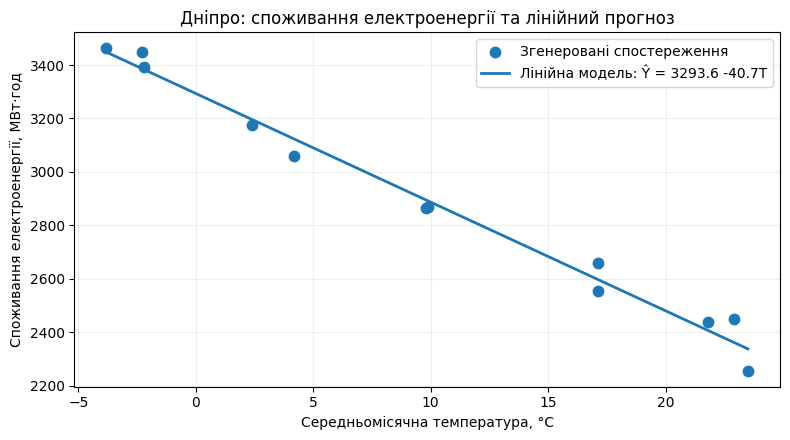

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(city_data["температура"], city_data["споживання_МВтгод"],
           s=56, label="Згенеровані спостереження", zorder=3)
x_line = np.linspace(city_data["температура"].min(), city_data["температура"].max(), 200)
ax.plot(x_line, a + b * x_line, linewidth=2,
        label=f"Лінійна модель: Ŷ = {a:.1f} {b:+.1f}T")
ax.set_xlabel("Середньомісячна температура, °C")
ax.set_ylabel("Споживання електроенергії, МВт·год")
ax.set_title("Дніпро: споживання електроенергії та лінійний прогноз")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Завдання 3. Передбачення, залишки й адекватність

Для кожного місяця обчислюємо залишок **e = фактичне споживання − прогноз**. Додатний залишок означає, що модель недооцінила споживання; від'ємний — переоцінила.

In [4]:
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]
residuals = city_data["залишок"]
ss_res = (residuals ** 2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot
rmse = np.sqrt(np.mean(residuals ** 2))
mae = np.mean(np.abs(residuals))

comparison = city_data.rename(columns={
    "споживання_МВтгод": "спостережено_МВтгод",
    "передбачення": "передбачено_МВтгод",
    "залишок": "залишок_МВтгод",
})[["місяць", "температура", "спостережено_МВтгод", "передбачено_МВтгод", "залишок_МВтгод"]]
display(comparison.round(2))
print(f"SS_res = {ss_res:.3f}")
print(f"SS_tot = {ss_tot:.3f}")
print(f"R² = {r_squared:.6f} ({r_squared * 100:.2f}%)")
print(f"RMSE = {rmse:.2f} МВт·год; MAE = {mae:.2f} МВт·год")
print(f"Середній залишок = {residuals.mean():.10f} МВт·год")

assert 0 <= r_squared <= 1
assert np.isclose(residuals.sum(), 0, atol=1e-8)

,місяць,температура,спостережено_МВтгод,передбачено_МВтгод,залишок_МВтгод
0,1,-3.8,3462.0,3448.05,13.95
1,2,-2.3,3447.0,3387.07,59.93
2,3,4.2,3060.0,3122.81,-62.81
3,4,9.9,2869.0,2891.09,-22.09
4,5,17.1,2659.0,2598.38,60.62
5,6,22.9,2451.0,2362.59,88.41
6,7,23.5,2257.0,2338.19,-81.19
7,8,21.8,2437.0,2407.31,29.69
8,9,17.1,2553.0,2598.38,-45.38
9,10,9.8,2866.0,2895.15,-29.15


SS_res = 30559.334
SS_tot = 1965470.667
R² = 0.984452 (98.45%)
RMSE = 50.46 МВт·год; MAE = 43.44 МВт·год
Середній залишок = -0.0000000000 МВт·год


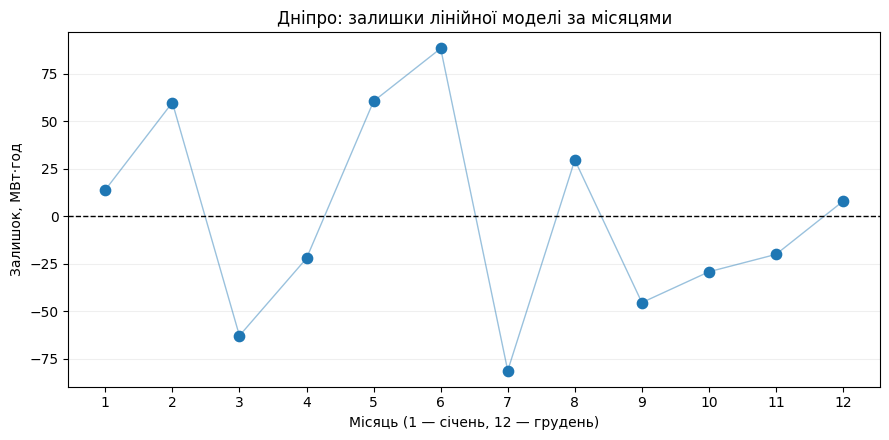

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(city_data["місяць"], residuals, s=55, zorder=3)
ax.plot(city_data["місяць"], residuals, alpha=0.45, linewidth=1)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xticks(city_data["місяць"])
ax.set_xlabel("Місяць (1 — січень, 12 — грудень)")
ax.set_ylabel("Залишок, МВт·год")
ax.set_title("Дніпро: залишки лінійної моделі за місяцями")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

**Числова оцінка:** R² = **0,98445** — температура в межах підібраної лінійної моделі пояснює близько **98,45%** вибіркового розкиду місячного споживання; близько **1,55%** залишається непоясненим. Помилка RMSE становить **50,46 МВт·год**, що близько до σ = 50 МВт·год шуму, закладеного у генератор.

**Конкретний аналіз залишків на графіку:** точки розташовані з обох боків нуля. Найбільший додатний залишок спостерігається **в червні (≈ +88,41 МВт·год)**, найбільший за модулем від'ємний — **у липні (≈ −81,19 МВт·год)**. У січні та грудні залишки додатні й порівняно невеликі (≈ +13,95 і +8,00), тоді як навесні та восени знаки змінюються. **Послідовного збільшення/зменшення або стійкої сезонної смуги одного знака не видно**; сусідні червень та липень навіть мають протилежні знаки. Це узгоджується з випадковим шумом, а не з пропущеною явною систематичною залежністю.

**Висновок щодо адекватності:** для опису **цього синтетичного року** найпростіша лінійна модель видається достатньо адекватною і за R², і за характером залишків. Водночас 12 точок замало для впевненої діагностики всіх можливих порушень; якість прогнозу на майбутніх даних ще не підтверджена.

## Завдання 4. Верифікація та валідація

**Верифікація (чи правильно реалізовано формулу).** Для січня з температурою **−3,8 °C** вручну підставляємо отримані `a` і `b` у формулу `a + b·(−3,8)`. Результат має точно збігатися (до похибки округлення) з клітинкою `передбачення` першого рядка. Додаткова технічна перевірка: порівняти `np.polyfit` із незалежним обчисленням коефіцієнтів через `np.linalg.lstsq`. Це перевіряє реалізацію методу, але **не доводить**, що саму модель правильно обрано для реального енергоспоживання.

**Валідація (чи модель придатна для мети).** Порівняння передбачень із тими самими 12 спостереженнями дає лише **внутрішню оцінку якості підгонки**. Для незалежної валідації потрібно зібрати відкладені, не використані під час оцінювання коефіцієнтів дані (наприклад, 12 місяців наступного року), обчислити на них MAE/RMSE та подивитися на зміщення залишків. Без цього не можна вважати доведеною прогностичну придатність до інших років або реальних умов.

In [6]:
# Конкретна верифікація: прогноз січня вручну і результат коду
jan_temp = float(city_data.loc[0, "температура"])
jan_manual = a + b * jan_temp
jan_from_code = float(city_data.loc[0, "передбачення"])
print(f"Січень, T={jan_temp:.1f} °C: вручну {jan_manual:.6f}, у таблиці {jan_from_code:.6f}")
assert np.isclose(jan_manual, jan_from_code)

# Незалежний математичний спосіб отримати ті самі коефіцієнти
X = np.column_stack((np.ones(len(city_data)), city_data["температура"].to_numpy()))
coefficients, *_ = np.linalg.lstsq(X, city_data["споживання_МВтгод"].to_numpy(), rcond=None)
print(f"np.linalg.lstsq: a={coefficients[0]:.6f}, b={coefficients[1]:.6f}")
assert np.allclose(coefficients, [a, b], atol=1e-10)
print("Верифікація коду пройдена. Незалежну валідацію на новому році не виконано: немає додаткових даних.")

Січень, T=-3.8 °C: вручну 3448.046347, у таблиці 3448.046347
np.linalg.lstsq: a=3293.561327, b=-40.653953
Верифікація коду пройдена. Незалежну валідацію на новому році не виконано: немає додаткових даних.


## Завдання 5. Пропозиція щодо вдосконалення

**Обраний варіант — не ускладнювати модель наявного навчального набору.** На 12 спостереженнях лінійна модель вже досягає **R² ≈ 0,9845**, а залишки не демонструють виразної систематичної форми. Додавання квадратичного члена або окремих сезонних коефіцієнтів підвищило б складність, зменшило число ступенів свободи та створило ризик підлаштування під випадковий шум. За принципом **компромісу точність–простота** поки доцільно залишити базове рівняння.

Якби на **незалежних** даних наступного року виникали повторювані сезонні похибки (скажімо, систематичне заниження влітку через кондиціонування), тоді можна було б перевірити додатковий фактор споживання на охолодження. Але в цій вибірці немає підстав ускладнювати модель лише задля ще вищого R².

## Контрольні питання — письмові відповіді

**1. Як розрізнити верифікацію і валідацію саме тут?**  
Верифікація підтверджує, що код обчислює прогноз за формулою `a + b·T`: для січня ручна підстановка `T = −3,8 °C` дає те саме число, що й стовпець `передбачення`, а `np.linalg.lstsq` підтверджує коефіцієнти `np.polyfit`. Валідація натомість оцінює, чи передбачатиме модель нове місячне споживання: для цього потрібні дані іншого періоду, які не брали участі в оцінюванні `a` і `b`. У роботі верифікацію здійснено; незалежна валідація ще потрібна.

**2. За якими незалежними ознаками класифікується модель?**  
За невизначеністю — **стохастична**, оскільки включає випадковий шум; за залежністю від часу — **статична**, бо кожен прогноз базується лише на температурі того ж місяця; за призначенням — **описова/прогнозна**, не балансова, не оптимізаційна й не імітаційна. Суперечності немає, бо кожна ознака відповідає на інше запитання про модель.

**3. Що показує R² і чи гарантує він правильність моделі або екстраполяції?**  
Значення **R² ≈ 0,9845** означає, що пряма пояснює приблизно **98,45% варіації споживання** серед цих 12 спостережень відносно моделі з одним константним середнім. Високий R² **не доводить причинності, коректності припущень або здатності прогнозувати поза даними**. Тут температури лежать приблизно від **−3,8 до +23,5 °C**, і на екстремальні температури поза цим інтервалом модель не перевірялась.

**4. Чому структура залишків важливіша за одну сумарну величину помилки?**  
Сума квадратів характеризує розмір похибок, але не показує, **де і як** вони виникають. Систематично додатні зимові залишки або вигнута форма на графіку могли б виявити пропущену нелінійність навіть за високого R². У наших даних найбільші відхилення припадають на червень (**+88,41**) і липень (**−81,19**) МВт·год; відсутність стійкого напряму підтримує висновок про допустимість простої лінійної залежності.

## Загальний висновок

Для Дніпра (варіант №5) згенеровано 12 синтетичних пар «температура — місячне споживання» й підібрано модель **Ŷ ≈ 3293,561 − 40,654·T**. Модель класифіковано як стохастичну, статичну, описову/прогнозну. Коефіцієнт **R² ≈ 0,9845**, а аналіз залишків не виявив очевидної систематичної закономірності. Перевірено правильність реалізації обчислень (верифікацію), але підкреслено, що **валідація на нових даних** ще потрібна. За принципом точність–простота на даному етапі ускладнення моделі не обґрунтоване.